In [1]:
import os
import os.path as op

import matplotlib.pyplot as plt

import hnn_core

from hnn_core import MPIBackend


from hnn_core.dipole import _rmse
from hnn_core.params import _short_name

from hnn_core import simulate_dipole, jones_2009_model
pathfig = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_HNN/figures/'



Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Trial 1: 150.0 ms...
Trial 1: 160.0 ms...
Trial 1: 170.0 ms...
Trial 1: 180.0 ms...
Trial 1: 190.0 ms...
Trial 1: 200.0 ms...
Trial 1: 210.0 ms...
Trial 1: 220.0 ms...
Trial 1: 230.0 ms...
Trial 1: 240.0 ms...
Trial 1: 250.0 ms...
Trial 1: 260.0 ms...
Trial 1: 270.0 ms...
Trial 1: 280.0 ms...
Trial 1: 290.0 ms...
Trial 1: 300.0 ms...
Trial 1: 310.0 ms...
Trial 1: 320.0 ms...
Trial 1: 330.0 ms...
Trial 1: 340.0 ms...
Trial 1: 350.0 ms...
Trial 1: 360.0 ms...
Trial 1: 370.0 ms...
Trial 1: 380.0 ms...
Trial 1: 390.0 ms...
Trial 1: 400.0 ms...
Trial 1: 410.0 ms...
Trial 1: 420.0 ms...

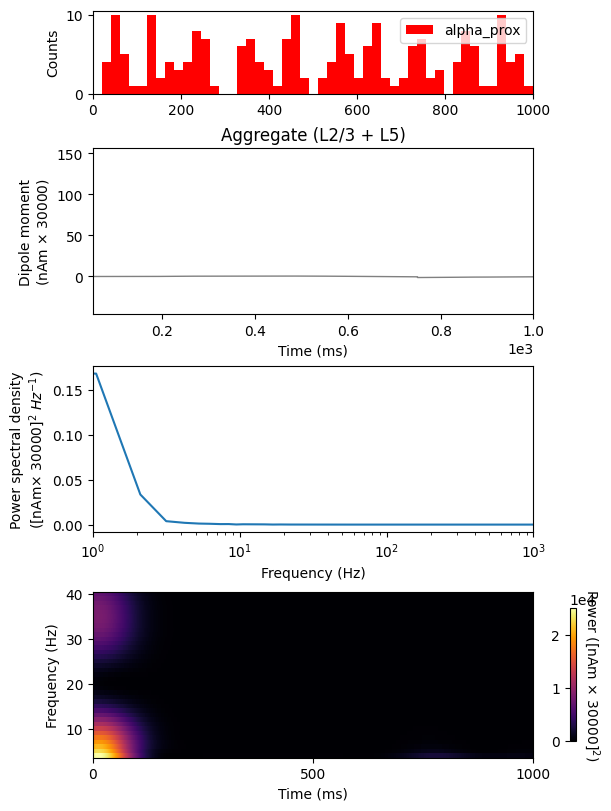

In [3]:
tstop = 1000

location = 'proximal'
burst_std = 20      
scale_factor = 30000
weights_ampa_p = {'L2_basket': 1.2e-7, 'L2_pyramidal': 0.6e-7, 'L5_pyramidal': 0.6e-7, 'L5_basket': 1.2e-7}     # max values taken from Jones 2009 for high mu; 

syn_delays_p = {'L2_basket': 4., 'L2_pyramidal': 5, 'L5_pyramidal': 5., 'L5_basket': 4}

net = jones_2009_model()

net.add_bursty_drive(
    'alpha_prox', tstart=50., burst_rate=10, burst_std=burst_std, numspikes=2,
    spike_isi=10, n_drive_cells=10, location=location,
    weights_ampa=weights_ampa_p, synaptic_delays=syn_delays_p, event_seed=284)

dpl = simulate_dipole(net, tstop=tstop, n_trials=1)[0]

dpl.scale(scale_factor)

import matplotlib.pyplot as plt
from hnn_core.viz import plot_dipole, plot_psd, plot_tfr_morlet
import numpy as np

fig, axes = plt.subplots(4, 1, constrained_layout=True, figsize=(6, 8), height_ratios=[0.5, 1, 1, 1])
tmin, tmax = 50, 1000  # exclude the initial burn-in period from the plots


net.cell_response.plot_spikes_hist(ax=axes[0], show=False)

dpl.plot(tmin=tmin, tmax=tmax, color='k', ax=axes[1], show=False)
#dpl_smooth.plot(tmin=tmin, tmax=tmax, color='r', ax=axes[1], show=False)
axes[1].set_xlim((tmin, tmax))

plot_psd(dpl, fmin=1., fmax=1e3, tmin=tmin, ax=axes[2], show=False)
axes[2].set_xscale('log')

freqs = np.arange(4, 41, 1)
plot_tfr_morlet(dpl, freqs, n_cycles=freqs/1000 * 500, tmin=0, tmax=tmax, layer='agg', padding='zeros', ax=axes[3],
                    colormap='inferno', colorbar=True, colorbar_inside=False, show=False)
axes[3].set_xlim((0, 1000))
axes[3].set_xticks(np.arange(0, 1001, 500))
# plt.tight_layout()

fig.savefig(os.path.join(pathfig, f'alpha_jones2009_joneset.png'), dpi=300)
fig.savefig(os.path.join(pathfig, f'alpha_jones2009_joneset.pdf'), dpi=300)